# Rol 3 + Rol 5 — Motor evolutivo y Meta-evaluación
**Examen práctico EC02 · "Del silbido al instrumento"**

Este notebook contiene la parte de los Roles 3 y 5 (fusionados al ser 4 integrantes):

| Sección | Qué se entrega |
|---|---|
| 1. Operadores (Rol 3) | 2+ variantes de selección, cruce y mutación · hijos siempre válidos · tests |
| 2. Comparación de operadores (Rol 3) | Tabla de 3 combinaciones · gráfico diversidad vs generación |
| 3. Robustez (Rol 5) | 10 corridas con semillas distintas · tabla + varianza |
| 4. Baseline (Rol 5) | AG vs búsqueda aleatoria con el mismo presupuesto · boxplot · test estadístico |
| 5. Sensibilidad (Rol 5) | Tornado de hiperparámetros y de genes |
| 6. Comparación auditiva + encuesta (Rol 5) | Audios, espectrogramas, encuesta ciega |

> **Importante:** mientras los Roles 1, 2 y 4 terminan sus módulos, este notebook usa
> `src/_provisional.py` (versiones mínimas con **las mismas firmas**). Cuando existan
> `rol1_codificacion.py`, `rol2_fitness.py` y `rol4_ag.py`, la celda de configuración los
> usa automáticamente y basta con **Restart & Run All** para regenerar todos los resultados.

In [1]:
import os, sys, importlib, time
RAIZ = os.path.abspath("..") if os.path.basename(os.getcwd()) == "notebooks" else os.getcwd()
sys.path.insert(0, RAIZ); os.chdir(RAIZ)

import numpy as np, pandas as pd, matplotlib.pyplot as plt
pd.set_option("display.width", 160); pd.set_option("display.max_colwidth", 60)
from src import rol3_operadores as op, rol3_experimentos as e3, rol5_analisis as an

SEMILLA = 42
an.entorno_reproducible(SEMILLA)
GRAF, TAB, AUD = "results/graficos", "results/tablas", "results/audios"
for c in (GRAF, TAB, AUD): os.makedirs(c, exist_ok=True)

python=3.13.16 | numpy=2.5.3 | scipy=1.18.1 | pandas=3.0.5 | matplotlib=3.11.2 | semilla=42


In [2]:
# Piezas de los otros roles: reales si ya existen, provisionales si no.
def _cargar(nombre):
    try:
        return importlib.import_module(f"src.{nombre}"), True
    except ModuleNotFoundError:
        return importlib.import_module("src._provisional"), False

rol1, ok1 = _cargar("rol1_codificacion")
rol2, ok2 = _cargar("rol2_fitness")
rol4, ok4 = _cargar("rol4_ag")
print(f"Rol 1 real: {ok1} | Rol 2 real: {ok2} | Rol 4 real: {ok4}")

N_GENES = len(rol1.GENES)
NOMBRES_GENES = [g[0] for g in rol1.GENES]
fitness = rol2.fitness
ejecutar_ag = rol4.ejecutar_ag

CONFIG_BASE = {"poblacion": 30, "n_genes": N_GENES, "generaciones": 50, "elitismo": 2}
print("Genes:", N_GENES, "| Presupuesto por corrida:",
      CONFIG_BASE["poblacion"] + CONFIG_BASE["generaciones"] * (CONFIG_BASE["poblacion"] - CONFIG_BASE["elitismo"]),
      "evaluaciones")

Rol 1 real: False | Rol 2 real: False | Rol 4 real: False
Genes: 14 | Presupuesto por corrida: 1430 evaluaciones


## 1. Operadores genéticos (Rol 3)

Convención del grupo: **todo individuo es un vector de floats en [0, 1]**; el Rol 1 lo
convierte a unidades físicas con `decodificar()`. Gracias a eso los operadores son genéricos
y la validez de los hijos se garantiza con un simple `reparar()` (recorte a [0, 1]).

| Tipo | Variante 1 | Variante 2 | Extra |
|---|---|---|---|
| Selección | Torneo k=3 | Ruleta | SUS |
| Cruce | Blend-α (BLX-α) | Uniforme | — |
| Mutación | Gaussiana | Uniforme | No uniforme |

**Hijos válidos:** BLX-α y la gaussiana pueden salirse de [0,1] → se reparan; uniforme y la
mutación uniforme nunca se salen; la no uniforme está acotada por construcción.

In [3]:
# Tests automáticos de los operadores (validez, presión selectiva, reproducibilidad...)
import tests.test_rol3 as T
for n, f in vars(T).items():
    if n.startswith("test_"):
        f(); print("✔", n)

✔ test_hijos_siempre_validos
✔ test_blend_extremos_se_reparan
✔ test_uniforme_solo_recombina
✔ test_torneo_presion_selectiva
✔ test_ruleta_y_sus_proporcionales
✔ test_no_uniforme_paso_decrece
✔ test_reproducible_con_semilla
✔ test_diversidad


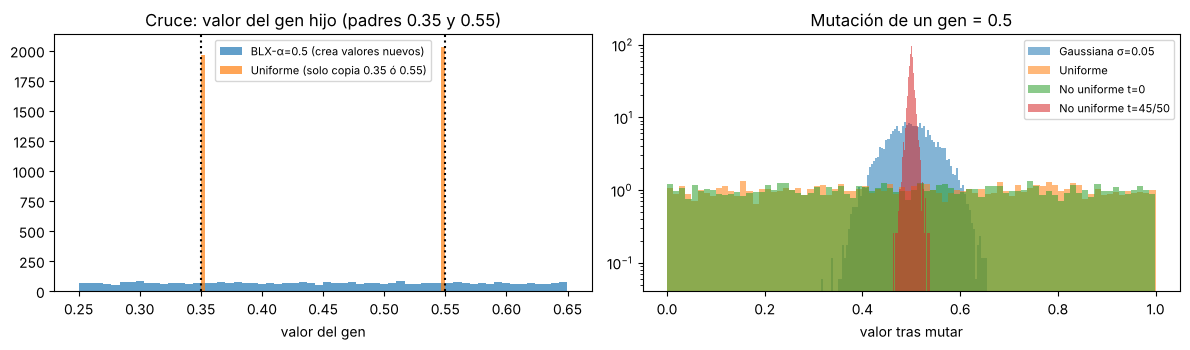

In [4]:
# Ilustración: cómo se reparten los hijos de 2 padres (1 gen) y el tamaño de paso de cada mutación
rng = np.random.default_rng(SEMILLA)
p1, p2 = np.array([0.35]), np.array([0.55])
blx = [op.cruce_blend(p1, p2, rng, alpha=0.5)[0][0] for _ in range(4000)]
uni = [op.cruce_uniforme(p1, p2, rng)[0][0] for _ in range(4000)]
x = np.full(1, 0.5)
gau = [op.mutacion_gaussiana(x, rng, 1.0, 0.05)[0] for _ in range(4000)]
mun = [op.mutacion_uniforme(x, rng, 1.0)[0] for _ in range(4000)]
nu0 = [op.mutacion_no_uniforme(x, rng, 1.0, 0, 50)[0] for _ in range(4000)]
nuT = [op.mutacion_no_uniforme(x, rng, 1.0, 45, 50)[0] for _ in range(4000)]

fig, ax = plt.subplots(1, 2, figsize=(12, 3.6))
ax[0].hist(blx, 60, alpha=.7, label="BLX-α=0.5 (crea valores nuevos)")
ax[0].hist(uni, 60, alpha=.7, label="Uniforme (solo copia 0.35 ó 0.55)")
ax[0].axvline(.35, c="k", ls=":"); ax[0].axvline(.55, c="k", ls=":")
ax[0].set(title="Cruce: valor del gen hijo (padres 0.35 y 0.55)", xlabel="valor del gen"); ax[0].legend(fontsize=8)
for d, n in ((gau, "Gaussiana σ=0.05"), (mun, "Uniforme"), (nu0, "No uniforme t=0"), (nuT, "No uniforme t=45/50")):
    ax[1].hist(d, 80, alpha=.55, label=n, density=True)
ax[1].set(title="Mutación de un gen = 0.5", xlabel="valor tras mutar", yscale="log"); ax[1].legend(fontsize=8)
fig.tight_layout(); fig.savefig(f"{GRAF}/rol3_operadores_ilustracion.png", dpi=130)

## 2. Comparación de 3 combinaciones de operadores (Rol 3)

Las 3 combinaciones se diseñaron para cubrir el espectro **explotación ↔ exploración**:

| Combinación | Selección | Cruce | Mutación | Hipótesis |
|---|---|---|---|---|
| C1 Explotación | Torneo k=3 | BLX-α=0.3 | Gaussiana σ=0.03 | Converge rápido, riesgo de estancarse |
| C2 Exploración | Ruleta | Uniforme | Uniforme | Mantiene diversidad, afina poco |
| C3 Balance | Torneo k=3 | BLX-α=0.5 | No uniforme | Explora al inicio, explota al final |

Mismo presupuesto, misma población inicial (misma semilla) y 5 semillas por combinación.

In [5]:
t0 = time.time()
df_ops, hist_ops = e3.comparar_combinaciones(ejecutar_ag, fitness, CONFIG_BASE, seeds=range(5))
tabla_ops = e3.tabla_resumen(df_ops)
df_ops.to_csv(f"{TAB}/rol3_corridas_operadores.csv", index=False)
tabla_ops.to_csv(f"{TAB}/rol3_tabla_comparativa.csv")
print(f"{time.time()-t0:.0f} s")
tabla_ops

52 s


,fitness_media,fitness_std,mejor,peor,gen_al_95,div_gen10,div_final
combinacion,,,,,,,
C3 Balance (torneo + blend α=0.5 + no-uniforme),0.9968,0.0023,0.9988,0.9931,35.6,0.4219,0.0199
C1 Explotación (torneo + blend α=0.3 + gaussiana σ=0.03),0.9932,0.0019,0.9952,0.9904,43.8,0.1372,0.0403
C2 Exploración (ruleta + uniforme + mut. uniforme),0.9928,0.0018,0.9949,0.9900,40.6,0.6942,0.6416


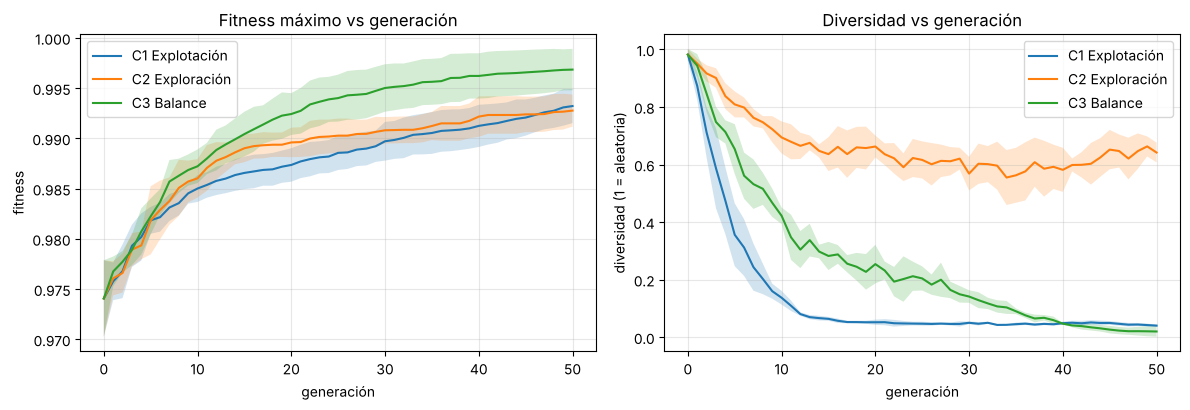

In [6]:
e3.graficar(hist_ops, GRAF);

In [7]:
mejor_combo = tabla_ops.index[0]
print("Combinación elegida (mayor fitness medio):", mejor_combo)
for nombre, fila in tabla_ops.iterrows():
    print(f"- {nombre.split(' (')[0]}: fitness {fila.fitness_media:.4f} ± {fila.fitness_std:.4f}, "
          f"diversidad en gen 10 = {fila.div_gen10:.2f}, final = {fila.div_final:.2f}")
OPERADORES_ELEGIDOS = op.COMBINACIONES[mejor_combo]
CONFIG = {**CONFIG_BASE, "operadores": OPERADORES_ELEGIDOS}

Combinación elegida (mayor fitness medio): C3 Balance (torneo + blend α=0.5 + no-uniforme)
- C3 Balance: fitness 0.9968 ± 0.0023, diversidad en gen 10 = 0.42, final = 0.02
- C1 Explotación: fitness 0.9932 ± 0.0019, diversidad en gen 10 = 0.14, final = 0.04
- C2 Exploración: fitness 0.9928 ± 0.0018, diversidad en gen 10 = 0.69, final = 0.64


**Lectura (exploración vs. explotación):**

- **C1 (explotación)**: torneo + pasos gaussianos pequeños → la diversidad cae a ≈0.05 antes de
  la generación 15: la población se concentra alrededor del mejor y a partir de ahí solo afina
  localmente (riesgo de convergencia prematura).
- **C2 (exploración)**: ruleta (baja presión selectiva, porque el fitness está comprimido en un rango
  pequeño) + mutación uniforme (saltos a cualquier punto) → la diversidad se queda alta (≈0.6);
  encuentra zonas buenas pero **no afina**.
- **C3 (balance)**: la mutación no uniforme da pasos grandes al principio y diminutos al final;
  la diversidad baja de forma gradual y obtiene el **mejor fitness final**.

El operador que más empuja a la **exploración** es la mutación uniforme (y la ruleta, por su baja
presión); los que más empujan a la **explotación** son el torneo y la mutación gaussiana con σ chico.
*(Los números exactos se recalculan solos al conectar el fitness real del Rol 2.)*

## 3. Robustez: 10 corridas con semillas distintas (Rol 5)

In [8]:
t0 = time.time()
df_sem, res_sem = an.corridas_semillas(ejecutar_ag, CONFIG, fitness, seeds=range(10))
df_sem.to_csv(f"{TAB}/rol5_corridas_semillas.csv", index=False)
print(f"{time.time()-t0:.0f} s")
display(df_sem.round(5))
an.resumen_varianza(df_sem)

34 s


,semilla,fitness_final,fitness_gen0,evaluaciones,diversidad_final
0,0,0.99821,0.97454,1430,0.01033
1,1,0.99881,0.96715,1430,0.00966
2,2,0.99795,0.97860,1430,0.00779
3,3,0.99613,0.97407,1430,0.01588
4,4,0.99313,0.97600,1430,0.05586
5,5,0.99488,0.97095,1430,0.03704
6,6,0.99596,0.97371,1430,0.02335
7,7,0.99763,0.97323,1430,0.00957
8,8,0.99753,0.97354,1430,0.01707
9,9,0.99809,0.97499,1430,0.00939


n          10.00000
media       0.99683
desv        0.00178
CV_%        0.17863
min         0.99313
mediana     0.99758
max         0.99881
dtype: float64

## 4. ¿Es mejor que una búsqueda aleatoria? (Rol 5)

Para que la comparación sea justa, la búsqueda aleatoria recibe **exactamente el mismo número
de evaluaciones de fitness** que cada corrida del AG. Métricas:

- **Fitness final** de cada método en las 10 semillas (boxplot).
- **Test de Mann-Whitney U** unilateral (H₁: AG > aleatoria) — no asume normalidad.
- **A₁₂ de Vargha-Delaney** = P(una corrida del AG supere a una aleatoria). 0.5 = empate, ≥ 0.71 = efecto grande.
- **Curva mejor-fitness vs evaluaciones**: muestra *cuándo* se separan los métodos.

In [9]:
df_base, prueba, curvas_al = an.ag_vs_aleatoria(res_sem, fitness, N_GENES, seeds=range(10))
df_base.to_csv(f"{TAB}/rol5_ag_vs_aleatoria.csv", index=False)
pd.Series(prueba).to_frame("valor")

,valor
media_AG,0.996832
media_aleatoria,0.980997
mejora_%,1.614242
U,100.0
p_valor,0.000091
A12,1.0
AG_gana_en,10/10 semillas


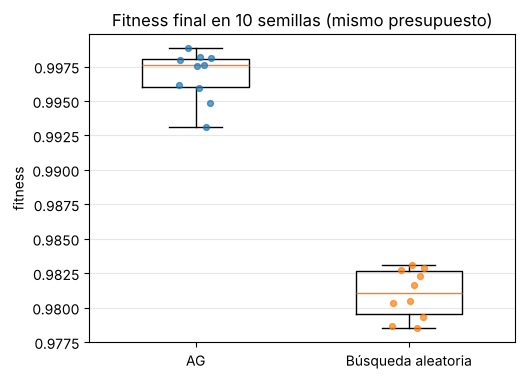

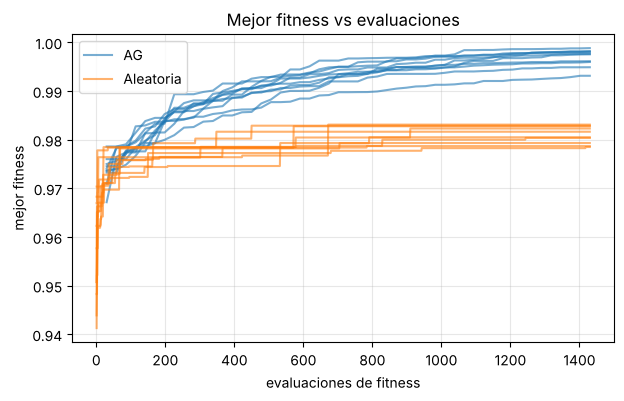

In [10]:
an.graficar_boxplot(df_base, GRAF)
an.graficar_curvas_vs_baseline(res_sem, curvas_al, GRAF);

## 5. Análisis de sensibilidad — gráficos tornado (Rol 5)

**a) Hiperparámetros:** cada factor se lleva a un valor bajo y uno alto dejando el resto en la
configuración base; la longitud de la barra indica cuánto cambia el fitness final.

139 s


,factor,valor_bajo,valor_alto,fitness_bajo,fitness_alto,base,rango
0,poblacion,10.00,60.0,0.9925,0.9978,0.9983,0.0053
1,operadores.alpha,0.00,1.0,0.9931,0.9973,0.9983,0.0043
2,operadores.b,0.50,5.0,0.9984,0.9968,0.9983,0.0016
3,operadores.k,2.00,7.0,0.9975,0.9983,0.9983,0.0008
4,operadores.pm,0.02,0.3,0.9974,0.9969,0.9983,0.0005
5,elitismo,0.00,6.0,0.9981,0.9982,0.9983,0.0000


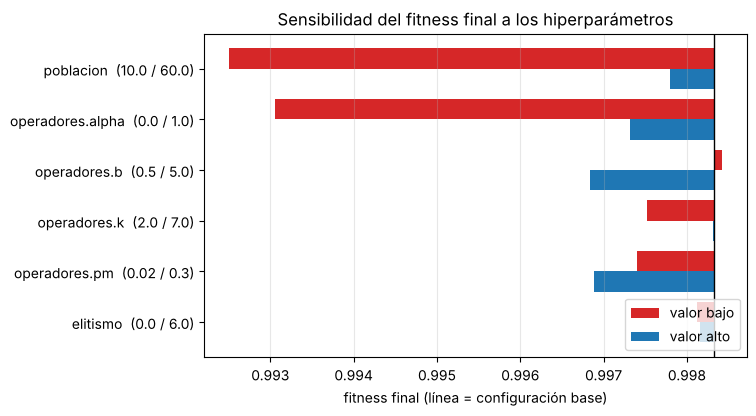

In [11]:
FACTORES = {
    "poblacion": (10, 60),
    "elitismo": (0, 6),
    "operadores.pm": (0.02, 0.30),
    "operadores.alpha": (0.0, 1.0),
    "operadores.k": (2, 7),
}
if OPERADORES_ELEGIDOS.get("mutacion") == "gaussiana":
    FACTORES["operadores.sigma"] = (0.01, 0.20)
elif OPERADORES_ELEGIDOS.get("mutacion") == "no_uniforme":
    FACTORES["operadores.b"] = (0.5, 5.0)

t0 = time.time()
df_tor = an.sensibilidad_hiperparametros(ejecutar_ag, CONFIG, fitness, FACTORES, seeds=range(3))
df_tor.to_csv(f"{TAB}/rol5_tornado_hiperparametros.csv", index=False)
print(f"{time.time()-t0:.0f} s")
an.graficar_tornado(df_tor, "Sensibilidad del fitness final a los hiperparámetros", GRAF,
                    "rol5_tornado_hiperparametros.png")
df_tor.round(4)

**b) Genes:** alrededor del mejor individuo encontrado, cada gen se mueve ±0.2 (en escala
normalizada). Complementa el análisis del Rol 1 (fitness vs. variación de cada gen).

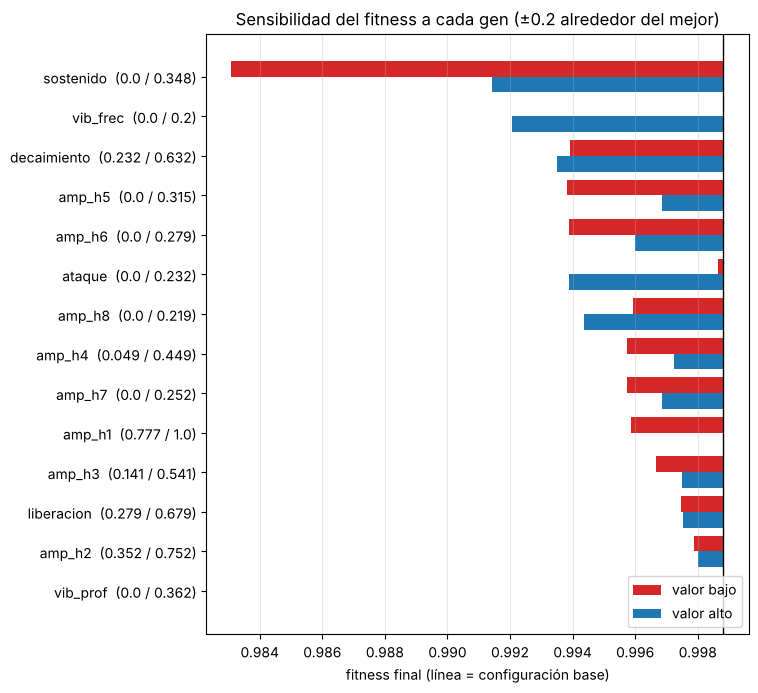

In [12]:
mejor = max(res_sem, key=lambda r: r["mejor_fit"])
df_gen = an.sensibilidad_genes(fitness, mejor["mejor"], NOMBRES_GENES, delta=0.2)
df_gen.to_csv(f"{TAB}/rol5_tornado_genes.csv", index=False)
an.graficar_tornado(df_gen, "Sensibilidad del fitness a cada gen (±0.2 alrededor del mejor)", GRAF,
                    "rol5_tornado_genes.png");

## 6. Comparación auditiva y encuesta (Rol 5)

Los 4 audios que pide el enunciado: **silbido, Gen 0 (mejor individuo de la población inicial),
referencia y mejor evolucionado**, todos tocando la melodía detectada.

Notas MIDI: [72, 74, 76, 77, 79] 
Duraciones: [0.35 0.35 0.35 0.35 0.98]


**Silbido**

**Gen 0**

**Referencia**

**Mejor evolucionado**

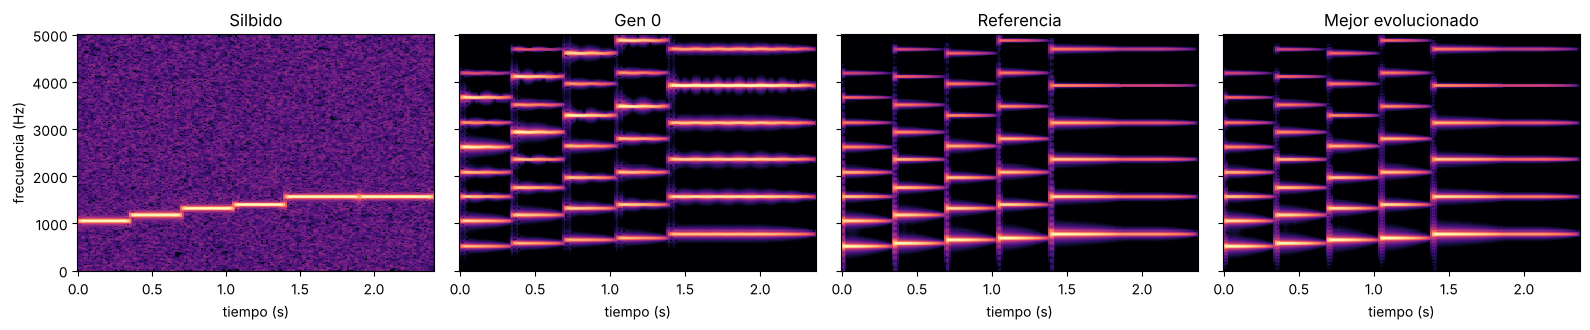

In [13]:
import soundfile as sf
SR = 22050
RUTA_SILBIDO = "data/silbido.wav" if os.path.exists("data/silbido.wav") else "data/silbido_prueba.wav"
if not os.path.exists(RUTA_SILBIDO):
    rol1.crear_silbido_prueba(RUTA_SILBIDO) if hasattr(rol1, "crear_silbido_prueba") else None
TRANSPOSICION = -12   # el silbido suele estar 1-2 octavas arriba del registro del instrumento

notas, durs = rol1.extraer_notas(RUTA_SILBIDO)
notas = [n + TRANSPOSICION for n in notas]
print("Notas MIDI:", notas, "\nDuraciones:", np.round(durs, 2))

silbido, _ = sf.read(RUTA_SILBIDO)
audios = {
    "Silbido": silbido,
    "Gen 0": rol2.sintetizar_instrumento(notas, durs, rol1.decodificar(mejor["mejor_gen0"])),
    "Referencia": rol2.sintetizar_instrumento(notas, durs, rol2.GEN_REFERENCIA)
                  if hasattr(rol2, "GEN_REFERENCIA") else sf.read("data/referencia.wav")[0],
    "Mejor evolucionado": rol2.sintetizar_instrumento(notas, durs, rol1.decodificar(mejor["mejor"])),
}
rutas = {}
for n, y in audios.items():
    rutas[n] = f"{AUD}/{n.lower().replace(' ', '_')}.wav"
    sf.write(rutas[n], 0.9 * y / np.max(np.abs(y)), SR, subtype="PCM_16")
an.comparacion_auditiva(audios, SR, GRAF);

In [14]:
# Encuesta CIEGA: los audios se renombran clip_A, clip_B... en orden aleatorio.
clave = an.crear_encuesta({k: v for k, v in rutas.items() if k != "Silbido"}, "results/encuesta")
print("Archivos en results/encuesta: clips, respuestas.csv (plantilla), instrucciones.md")
print("(La clave está en clave.json — no mostrarla a los encuestados.)")

Archivos en results/encuesta: clips, respuestas.csv (plantilla), instrucciones.md
(La clave está en clave.json — no mostrarla a los encuestados.)


In [15]:
# Una vez llenado results/encuesta/respuestas.csv con 5–10 personas:
INSTRUMENTO = "piano"
try:
    tabla_enc, conclusion = an.analizar_encuesta("results/encuesta", INSTRUMENTO)
    display(tabla_enc); print(conclusion)
except Exception as e:
    print("Encuesta aún sin respuestas:", type(e).__name__)

None

Encuesta aún sin respuestas: llena results/encuesta/respuestas.csv


## 7. Limitaciones del AG en este dominio (borrador para el informe)

1. **Costo de evaluación:** cada individuo exige sintetizar audio y calcular una STFT; por eso el
   fitness se mide sobre 1–2 notas y no sobre la melodía completa.
2. **El fitness espectral no es el oído humano:** un mejor puntaje en dB no garantiza que suene
   "más a piano"; de ahí la encuesta auditiva como validación externa.
3. **Límite del sintetizador:** el AG solo puede encontrar timbres que el modelo de síntesis
   aditiva puede producir (sin ruido de martillo, resonancia de caja, etc.).
4. **Dependencia del pitch:** si la detección de notas falla, el AG no lo puede corregir —
   evoluciona el timbre, no la melodía.
5. **Superficie con mesetas:** genes como el vibrato o los armónicos altos casi no cambian el
   fitness (ver tornado de genes) → deriva genética en esos genes.
6. **Variabilidad entre semillas:** reportada en la sección 3 (CV%).